# 01 · Embed ImageNet-1k with CLIP

**Runtime:** A100 GPU with High-RAM on (L4 also works).

This notebook:
1. Runs a **smoke test** on one shard to measure throughput.
2. Embeds all 40 training shards, saving each shard to Drive as it finishes. Rerunning skips finished shards.
3. Embeds 1,000 validation queries (one per class).
4. Checks the outputs before you leave the GPU runtime.

All settings come from `LAB2_*` environment variables (defaults below). To override one, set
`os.environ["LAB2_..."]` in a cell above the config cell.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch==2.32.0"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


## Configuration

In [2]:
def env_str(name, default):
    return os.environ.get(name, default)


def env_int(name, default):
    return int(os.environ.get(name, default))


def env_float(name, default):
    return float(os.environ.get(name, default))


def parse_ids(spec):
    """'0-39' -> [0..39]; '0,3,5' -> [0, 3, 5]; '7' -> [7]."""
    ids = []
    for part in spec.split(","):
        part = part.strip()
        if "-" in part:
            lo, hi = part.split("-")
            ids.extend(range(int(lo), int(hi) + 1))
        elif part:
            ids.append(int(part))
    return ids


LAB2_ROOT = env_str("LAB2_ROOT", "/content/drive/MyDrive/cap6938-hw2")       # Drive folder for outputs
LAB2_LOCAL_DATA = env_str("LAB2_LOCAL_DATA", "/content/data")                  # local disk for parquet files
LAB2_DATASET = env_str("LAB2_DATASET", "benjamin-paine/imagenet-1k-256x256")
LAB2_MODEL = env_str("LAB2_MODEL", "ViT-L-14-quickgelu")                        # open_clip model name (OpenAI weights need QuickGELU)
LAB2_PRETRAINED = env_str("LAB2_PRETRAINED", "openai")                          # open_clip weights tag
LAB2_BATCH_SIZE = env_int("LAB2_BATCH_SIZE", 256)                               # 512 on A100, 256 on L4
LAB2_NUM_WORKERS = env_int("LAB2_NUM_WORKERS", os.cpu_count() or 2)             # image-decoding workers
LAB2_SHARDS = parse_ids(env_str("LAB2_SHARDS", "0-39"))                         # training shards to embed
LAB2_NUM_TRAIN_FILES = env_int("LAB2_NUM_TRAIN_FILES", 40)
LAB2_NUM_VAL_FILES = env_int("LAB2_NUM_VAL_FILES", 2)
LAB2_EXPECTED_TRAIN_ROWS = env_int("LAB2_EXPECTED_TRAIN_ROWS", 1281167)
LAB2_SEED = env_int("LAB2_SEED", 42)
LAB2_QUERIES_PER_CLASS = env_int("LAB2_QUERIES_PER_CLASS", 1)
LAB2_SMOKE_ROWS = env_int("LAB2_SMOKE_ROWS", 4096)                              # rows timed in the smoke test
LAB2_KEEP_PARQUET = env_int("LAB2_KEEP_PARQUET", 0)                             # 1 keeps parquet files after embedding
LAB2_ALLOW_CPU = env_int("LAB2_ALLOW_CPU", 0)                                   # 1 allows running without a GPU (testing only)

EMB_DIR = f"{LAB2_ROOT}/embeddings"
os.makedirs(EMB_DIR, exist_ok=True)
os.makedirs(LAB2_LOCAL_DATA, exist_ok=True)
print(f"model={LAB2_MODEL}/{LAB2_PRETRAINED} batch={LAB2_BATCH_SIZE} workers={LAB2_NUM_WORKERS} "
      f"shards={LAB2_SHARDS[0]}..{LAB2_SHARDS[-1]} ({len(LAB2_SHARDS)})")
print("outputs ->", EMB_DIR)

model=ViT-L-14-quickgelu/openai batch=256 workers=12 shards=0..39 (40)
outputs -> /content/drive/MyDrive/cap6938-hw2/embeddings


## Imports, helpers and model

In [3]:
import io, json, time
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import torch
import open_clip
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import hf_hub_download


def train_file(i):
    return f"data/train-{i:05d}-of-{LAB2_NUM_TRAIN_FILES:05d}.parquet"


def val_file(i):
    return f"data/validation-{i:05d}-of-{LAB2_NUM_VAL_FILES:05d}.parquet"


def fetch(filename):
    """Return a local path for a dataset file, downloading it only if it is not already on disk."""
    local = os.path.join(LAB2_LOCAL_DATA, filename)
    if os.path.exists(local):
        return local
    return hf_hub_download(repo_id=LAB2_DATASET, repo_type="dataset",
                           filename=filename, local_dir=LAB2_LOCAL_DATA)


def image_bytes_column(table):
    """The Hugging Face Image feature is stored as struct<bytes, path>; return the bytes array."""
    col = table.column("image").combine_chunks()
    if pa.types.is_struct(col.type):
        col = col.field("bytes")
    return col


def class_names_from(path):
    meta = pq.read_schema(path).metadata or {}
    if b"huggingface" in meta:
        return json.loads(meta[b"huggingface"])["info"]["features"]["label"]["names"]
    from datasets import load_dataset_builder
    return load_dataset_builder(LAB2_DATASET).info.features["label"].names


def save_npy(path, arr):
    """Write to a temp file, then rename, so a disconnect never leaves a half-written file."""
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        np.save(f, arr)
    os.replace(tmp, path)


def save_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=1)
    os.replace(tmp, path)


class ParquetImages(Dataset):
    def __init__(self, table, transform):
        self.blobs = image_bytes_column(table)
        self.transform = transform

    def __len__(self):
        return len(self.blobs)

    def __getitem__(self, i):
        img = Image.open(io.BytesIO(self.blobs[i].as_py())).convert("RGB")
        return self.transform(img)


device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu" and not LAB2_ALLOW_CPU:
    raise RuntimeError("No GPU found. Runtime > Change runtime type > A100 GPU (or L4), then rerun all cells.")
torch.backends.cuda.matmul.allow_tf32 = True

# OpenAI CLIP weights were trained with QuickGELU. A model config without it loads the weights
# but computes different (worse) embeddings, so force it whenever the weights ask for it.
pretrained_cfg = open_clip.get_pretrained_cfg(LAB2_MODEL, LAB2_PRETRAINED) if LAB2_PRETRAINED else {}
model, _, preprocess = open_clip.create_model_and_transforms(
    LAB2_MODEL, pretrained=LAB2_PRETRAINED or None,
    force_quick_gelu=bool(pretrained_cfg.get("quick_gelu", False)))
model = model.to(device).eval()
EMB_DIM = model.visual.output_dim
IMG_SIZE = model.visual.image_size
IMG_SIZE = IMG_SIZE[0] if isinstance(IMG_SIZE, (tuple, list)) else IMG_SIZE

loader_kwargs = {}
if LAB2_NUM_WORKERS > 0:
    loader_kwargs = {"prefetch_factor": 4,
                     "multiprocessing_context": "fork" if sys.platform == "linux" else None}


@torch.no_grad()
def embed_table(table):
    """Embed every image in a pyarrow table, in row order. Returns fp16 [n, EMB_DIM], L2-normalised."""
    loader = DataLoader(ParquetImages(table, preprocess), batch_size=LAB2_BATCH_SIZE, shuffle=False,
                        num_workers=LAB2_NUM_WORKERS, pin_memory=(device == "cuda"), **loader_kwargs)
    out = []
    for x in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            f = model.encode_image(x)
        f = torch.nn.functional.normalize(f.float(), dim=-1)
        out.append(f.half().cpu())
    return torch.cat(out).numpy()


print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")
print(f"torch {torch.__version__} | open_clip {open_clip.__version__} | pyarrow {pa.__version__}")
print(f"embedding dim {EMB_DIM}, input {IMG_SIZE}px, CPUs {os.cpu_count()}")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

device: cuda NVIDIA A100-SXM4-40GB
torch 2.11.0+cu130 | open_clip 2.32.0 | pyarrow 23.0.1
embedding dim 768, input 224px, CPUs 12


## Smoke test

This embeds the first `LAB2_SMOKE_ROWS` rows of the first shard and compares two numbers:
- **GPU-only throughput** on random tensors. This is the most the GPU can do.
- **End-to-end throughput**, which includes decoding the images. This is what the full run gets.

If end-to-end is much lower than GPU-only, image decoding is the bottleneck. Raise
`LAB2_NUM_WORKERS` (or use a runtime with more CPUs).

data/train-00000-of-00040.parquet: reconstructing file:   0%|          |  0.00B /  413MB            

data/train-00000-of-00040.parquet: downloading bytes:           |  0.00B            

1000 classes (1001 names); shard 0 smoke slice: 4096 rows


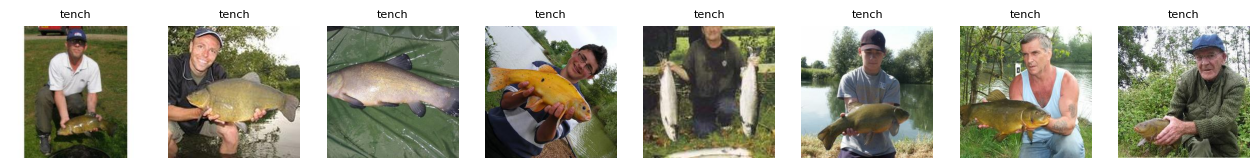

In [4]:
p0 = fetch(train_file(LAB2_SHARDS[0]))
CLASS_NAMES = class_names_from(p0)
# The dataset's label feature ends with a 'none' placeholder (1,001 names for 1,000 classes).
NUM_CLASSES = len(CLASS_NAMES) - (CLASS_NAMES[-1] == "none")
save_json(f"{EMB_DIR}/class_names.json", CLASS_NAMES)

smoke = pq.read_table(p0).slice(0, LAB2_SMOKE_ROWS)
smoke_labels = smoke.column("label").to_numpy()
blobs = image_bytes_column(smoke)
print(f"{NUM_CLASSES} classes ({len(CLASS_NAMES)} names); shard {LAB2_SHARDS[0]} smoke slice: {smoke.num_rows} rows")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, range(8)):
    ax.imshow(Image.open(io.BytesIO(blobs[i].as_py())))
    ax.set_title(CLASS_NAMES[smoke_labels[i]].split(",")[0][:18], fontsize=8)
    ax.axis("off")
plt.show()

In [5]:
# GPU-only ceiling: random inputs, no decoding.
x = torch.randn(LAB2_BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=device)
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
    for _ in range(2):
        model.encode_image(x)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    n_batches = 5
    for _ in range(n_batches):
        model.encode_image(x)
    if device == "cuda":
        torch.cuda.synchronize()
gpu_ips = n_batches * LAB2_BATCH_SIZE / (time.perf_counter() - t0)
del x

# End-to-end: decode + preprocess + embed.
t0 = time.perf_counter()
smoke_emb = embed_table(smoke)
e2e_ips = len(smoke_emb) / (time.perf_counter() - t0)

norms = np.linalg.norm(smoke_emb.astype(np.float32), axis=1)
assert smoke_emb.shape == (smoke.num_rows, EMB_DIM), smoke_emb.shape
assert np.allclose(norms, 1.0, atol=1e-3), (norms.min(), norms.max())

eta_h = LAB2_EXPECTED_TRAIN_ROWS / e2e_ips / 3600
print(f"GPU-only: {gpu_ips:,.0f} img/s | end-to-end: {e2e_ips:,.0f} img/s "
      f"({e2e_ips / gpu_ips:.0%} of GPU ceiling)")
print(f"estimated embedding time for {LAB2_EXPECTED_TRAIN_ROWS:,} images: {eta_h:.2f} h "
      f"(plus about 10-20 s download per shard)")
save_json(f"{EMB_DIR}/smoke_test.json", {"gpu_only_img_per_s": round(gpu_ips, 1),
                                         "end_to_end_img_per_s": round(e2e_ips, 1),
                                         "rows": int(len(smoke_emb)), "batch_size": LAB2_BATCH_SIZE,
                                         "num_workers": LAB2_NUM_WORKERS,
                                         "device": torch.cuda.get_device_name(0) if device == "cuda" else "cpu"})
del smoke, smoke_emb, blobs

GPU-only: 676 img/s | end-to-end: 418 img/s (62% of GPU ceiling)
estimated embedding time for 1,281,167 images: 0.85 h (plus about 10-20 s download per shard)


## Embed the training set

Each shard is written to `embeddings/train_NN.npy` (fp16) and `train_NN_labels.npy` (int16), and its
row count and timings are added to `manifest.json`. **If the runtime disconnects, rerun this
notebook from the top.** Finished shards are skipped.

In [6]:
MANIFEST = f"{EMB_DIR}/manifest.json"


def load_manifest():
    if os.path.exists(MANIFEST):
        with open(MANIFEST) as f:
            return json.load(f)
    return {"dataset": LAB2_DATASET, "model": LAB2_MODEL, "pretrained": LAB2_PRETRAINED,
            "dim": EMB_DIM, "shards": {}}


manifest = load_manifest()
assert manifest["model"] == LAB2_MODEL and manifest["dim"] == EMB_DIM, \
    "manifest.json was written by a different model; use a new LAB2_ROOT"

for i in LAB2_SHARDS:
    emb_path, lab_path = f"{EMB_DIR}/train_{i:02d}.npy", f"{EMB_DIR}/train_{i:02d}_labels.npy"
    if str(i) in manifest["shards"] and os.path.exists(emb_path) and os.path.exists(lab_path):
        print(f"shard {i:02d}: done, skipping")
        continue

    t0 = time.perf_counter()
    path = fetch(train_file(i))
    download_s = time.perf_counter() - t0

    table = pq.read_table(path)
    labels = table.column("label").to_numpy().astype(np.int16)
    t0 = time.perf_counter()
    emb = embed_table(table)
    embed_s = time.perf_counter() - t0
    assert emb.shape == (len(labels), EMB_DIM)

    save_npy(lab_path, labels)
    save_npy(emb_path, emb)
    manifest["shards"][str(i)] = {"rows": int(len(labels)), "download_s": round(download_s, 1),
                                  "embed_s": round(embed_s, 1),
                                  "img_per_s": round(len(labels) / embed_s, 1)}
    save_json(MANIFEST, manifest)
    del table, emb
    if not LAB2_KEEP_PARQUET:
        os.remove(path)
    print(f"shard {i:02d}: {len(labels):,} rows | download {download_s:.0f}s | "
          f"embed {embed_s:.0f}s ({len(labels) / embed_s:,.0f} img/s)")

shard 00: 32,030 rows | download 0s | embed 57s (565 img/s)


data/train-00001-of-00040.parquet: reconstructing file:   0%|          |  0.00B /  502MB            

data/train-00001-of-00040.parquet: downloading bytes:           |  0.00B            

shard 01: 32,030 rows | download 2s | embed 53s (605 img/s)


data/train-00002-of-00040.parquet: reconstructing file:   0%|          |  0.00B /  499MB            

...

data/train-00038-of-00040.parquet: downloading bytes:           |  0.00B            

shard 38: 32,029 rows | download 2s | embed 53s (603 img/s)


data/train-00039-of-00040.parquet: reconstructing file:   0%|          |  0.00B /  464MB            

data/train-00039-of-00040.parquet: downloading bytes:           |  0.00B            

shard 39: 32,029 rows | download 3s | embed 53s (600 img/s)


## Embed the queries

Queries come from the **validation** split, `LAB2_QUERIES_PER_CLASS` per class, chosen with seed
`LAB2_SEED`. They never overlap the database, so there are no self-matches to remove.
`queries_rows.npy` holds each query's row in the validation split (file 0, then file 1), which
`03_failures.ipynb` uses to show the query image.

In [7]:
Q_EMB, Q_LAB, Q_ROWS = (f"{EMB_DIR}/queries.npy", f"{EMB_DIR}/queries_labels.npy",
                        f"{EMB_DIR}/queries_rows.npy")
if os.path.exists(Q_EMB):
    print("queries: done, skipping")
else:
    vtable = pa.concat_tables([pq.read_table(fetch(val_file(i))) for i in range(LAB2_NUM_VAL_FILES)])
    vlabels = vtable.column("label").to_numpy()
    assert vlabels.min() >= 0, "validation split has unlabelled rows"
    rng = np.random.default_rng(LAB2_SEED)
    rows = []
    for c in np.unique(vlabels):
        idx = np.flatnonzero(vlabels == c)
        rows.extend(rng.choice(idx, size=min(LAB2_QUERIES_PER_CLASS, len(idx)), replace=False))
    rows = np.sort(np.asarray(rows, dtype=np.int32))

    t0 = time.perf_counter()
    q_emb = embed_table(vtable.take(pa.array(rows)))
    print(f"queries: {len(rows)} embedded in {time.perf_counter() - t0:.1f}s")
    save_npy(Q_ROWS, rows)
    save_npy(Q_LAB, vlabels[rows].astype(np.int16))
    save_npy(Q_EMB, q_emb)
    del vtable

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  352MB            

data/validation-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  351MB            

data/validation-00001-of-00002.parquet: downloading bytes:           |  0.00B            

queries: 1000 embedded in 3.6s


## Checks before leaving the GPU runtime

This writes each shard's **global offset** into `manifest.json`. Global id = offset + row within the
shard. Ids follow shard order 0, 1, …, 39 and are what the FAISS indexes return.

In [8]:
manifest = load_manifest()
missing = [i for i in range(LAB2_NUM_TRAIN_FILES) if str(i) not in manifest["shards"]]
if missing:
    print(f"NOT COMPLETE: {len(missing)} shards missing: {missing}. Rerun the cells above.")
else:
    offset = 0
    for i in range(LAB2_NUM_TRAIN_FILES):
        manifest["shards"][str(i)]["offset"] = offset
        offset += manifest["shards"][str(i)]["rows"]
    manifest["total_rows"] = offset
    save_json(MANIFEST, manifest)

    labels = np.concatenate([np.load(f"{EMB_DIR}/train_{i:02d}_labels.npy")
                             for i in range(LAB2_NUM_TRAIN_FILES)])
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    rng = np.random.default_rng(LAB2_SEED)
    sample_norms = []
    for i in rng.choice(LAB2_NUM_TRAIN_FILES, size=min(10, LAB2_NUM_TRAIN_FILES), replace=False):
        x = np.load(f"{EMB_DIR}/train_{i:02d}.npy", mmap_mode="r")
        pick = np.sort(rng.choice(len(x), size=min(1000, len(x)), replace=False))
        sample_norms.append(np.linalg.norm(x[pick].astype(np.float32), axis=1))
    sample_norms = np.concatenate(sample_norms)
    q_emb, q_lab = np.load(Q_EMB), np.load(Q_LAB)

    print(f"total rows: {offset:,} (expected {LAB2_EXPECTED_TRAIN_ROWS:,})")
    print(f"classes covered: {(counts > 0).sum()} / {NUM_CLASSES}; "
          f"rows per class min {counts.min()} max {counts.max()}")
    print(f"norms over {len(sample_norms):,} sampled vectors: "
          f"{sample_norms.min():.4f} .. {sample_norms.max():.4f}")
    print(f"queries: {q_emb.shape}, {len(np.unique(q_lab))} classes")

    assert offset == LAB2_EXPECTED_TRAIN_ROWS
    assert (counts > 0).sum() == NUM_CLASSES and len(counts) == NUM_CLASSES
    assert np.allclose(sample_norms, 1.0, atol=1e-3)
    assert q_emb.shape == (len(q_lab), EMB_DIM) and len(np.unique(q_lab)) == NUM_CLASSES

    embed_s = sum(s["embed_s"] for s in manifest["shards"].values())
    download_s = sum(s["download_s"] for s in manifest["shards"].values())
    print(f"embedding: {embed_s / 3600:.2f} h total, {offset / embed_s:,.0f} img/s average; "
          f"download {download_s / 60:.1f} min")
    print("ALL CHECKS PASSED")

total rows: 1,281,167 (expected 1,281,167)
classes covered: 1000 / 1000; rows per class min 732 max 1300
norms over 10,000 sampled vectors: 0.9998 .. 1.0002
queries: (1000, 768), 1000 classes
embedding: 0.59 h total, 603 img/s average; download 1.6 min
ALL CHECKS PASSED
